# EDA Sobre las pruebas del combine de la NFL

# 0.Preparación del entorno y carga del dataset


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path


%matplotlib inline


### Conectar con google drive para meter el dataset

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

# 1. Extraccion de los datos

In [ ]:
draft = pd.read_csv('/content/NFL_Combine_Since_2000.csv')
print(draft.shape)
draft.head(5)

(8968, 17)


,First,Last,Position,School,Height,Weight,40-yd Dash,Vertical Jump,Bench Press,Broad Jump,3-Cone Drill,20-yd Shuttle,Drafted,Team,Round,Pick,Year
0,John,Abraham,OLB,South Carolina,76,252,4.55,DNP,DNP,DNP,DNP,DNP,Y,New York Jets,1.0,13.0,2000
1,Shaun,Alexander,RB,Alabama,72,218,4.58,DNP,DNP,DNP,DNP,DNP,Y,Seattle Seahawks,1.0,19.0,2000
2,Darnell,Alford,OT,Boston Col.,76,334,5.56,25,23,94,8.48,4.98,Y,Kansas City Chiefs,6.0,188.0,2000
3,Kyle,Allamon,TE,Texas Tech,74,253,4.97,29,DNP,104,7.29,4.49,N,NaN,NaN,NaN,2000
4,Rashard,Anderson,CB,Jackson State,74,206,4.55,34,DNP,123,7.18,4.15,Y,Carolina Panthers,1.0,23.0,2000


In [ ]:
draft_pruebas = draft[["40-yd Dash","Vertical Jump","Bench Press","Broad Jump","3-Cone Drill","20-yd Shuttle", "Position","Drafted"]]
draft_pruebas.head(5)

,40-yd Dash,Vertical Jump,Bench Press,Broad Jump,3-Cone Drill,20-yd Shuttle,Position,Drafted
0,4.55,DNP,DNP,DNP,DNP,DNP,OLB,Y
1,4.58,DNP,DNP,DNP,DNP,DNP,RB,Y
2,5.56,25,23,94,8.48,4.98,OT,Y
3,4.97,29,DNP,104,7.29,4.49,TE,N
4,4.55,34,DNP,123,7.18,4.15,CB,Y


# 2. Analisis de variables y tipos de datos

Como variable objetivo voy a escoger "Drafted" para asi poder saber si en funcion de las marcas sacadas en el combine se puede saber si alguien sera elegido o no

In [ ]:
draft_pruebas.dtypes #Se observa que muchos de los valores estan como objetos al tener valores numericos y las letras del NDT, se resolvera luego cambiando el tipo de var

,0
40-yd Dash,object
Vertical Jump,object
Bench Press,object
Broad Jump,object
3-Cone Drill,object
20-yd Shuttle,object
Position,object
Drafted,object


In [ ]:
draft_pruebas.describe()

,40-yd Dash,Vertical Jump,Bench Press,Broad Jump,3-Cone Drill,20-yd Shuttle,Position,Drafted
count,8968,8968,8968,8968,8968,8968,8968,8968
unique,162,59,46,65,230,155,25,2
top,DNP,DNP,DNP,DNP,DNP,DNP,WR,Y
freq,929,2178,3573,2288,3894,3741,1246,5749


In [ ]:
draft["Drafted"].value_counts()

,count
Drafted,
Y,5749
N,3219


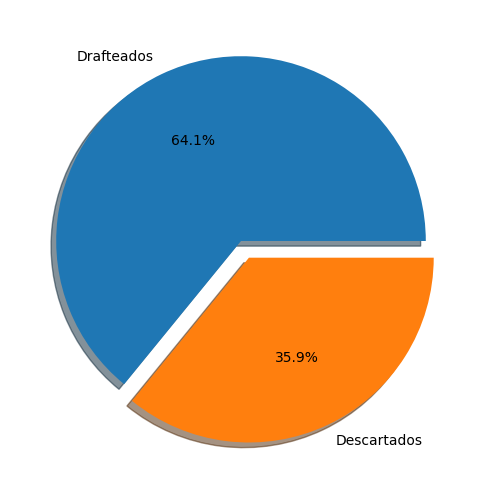

In [ ]:
grafico = draft['Drafted'].value_counts(normalize = True)

fig, ax = plt.subplots(figsize = (6,6))
ax.pie(grafico, labels=['Drafteados', 'Descartados'], autopct='%1.1f%%', shadow = True, explode = [0, 0.1]);

# 3. Datos missings

DNP en las pruebas del combine significa "Did Not Participate", lo que realmente nos dejaria el mismo resultado que no tener ningun valor en esas celdas, lo reemplazo por un valor nulo para sacar mejor los datos

In [ ]:
draft_pruebas = draft_pruebas.replace("DNP", np.nan)
draft_pruebas.isnull().sum()

,0
40-yd Dash,929
Vertical Jump,2178
Bench Press,3573
Broad Jump,2288
3-Cone Drill,3894
20-yd Shuttle,3741
Position,0
Drafted,0


In [ ]:
# Datos missing en valores porcentuales
_ = draft_pruebas.isnull().sum() / draft_pruebas.shape[0] * 100
_[_ > 0]

,0
40-yd Dash,10.359054
Vertical Jump,24.286351
Bench Press,39.841659
Broad Jump,25.512935
3-Cone Drill,43.421053
20-yd Shuttle,41.714987


Como tampoco quiero poner valores a jugadores que no realizaron todas las pruebas, voy a elimiar aquellas filas de jugadores cuyas pruebas tengan 4 o mas NTP

In [ ]:
draft_pruebas = draft_pruebas.dropna(thresh=draft_pruebas.shape[1] - 2) #pillo cuantas columnas tengo y le resto 2, filtro para decirle que cualquiera que tenga del resultado esas columnas a nulo se elimina
_ = draft_pruebas.isnull().sum() / draft_pruebas.shape[0] * 100
_[_ > 0] #Porcentajes

,0
40-yd Dash,1.494291
Vertical Jump,0.973808
Bench Press,24.328408
Broad Jump,1.494291
3-Cone Drill,15.614506
20-yd Shuttle,13.179987


Cambio de valores a numericos y categoricos

In [ ]:
columnas_numericas = ["40-yd Dash","Vertical Jump","Bench Press","Broad Jump","3-Cone Drill","20-yd Shuttle"] #Me guardo ya las numericas, asi luego no me dan errores con las categoricas al hacer operaciones
draft_pruebas[columnas_numericas] = draft_pruebas[columnas_numericas].apply(pd.to_numeric, errors='coerce') #como puse antes, estan en objeto por el NDT, los modifico todos a numeros para poder usarlos mejor
draft_pruebas.dtypes

,0
40-yd Dash,float64
Vertical Jump,float64
Bench Press,float64
Broad Jump,float64
3-Cone Drill,float64
20-yd Shuttle,float64
Position,object
Drafted,object


Tambien como sabemos en cualquier deporte un jugador no cumple la misma funcion que otro, por ende, las prueas fisicas tampoco tendran los mismos valores para un WR que para un LB (una posicion de ataque y otra de defensa)

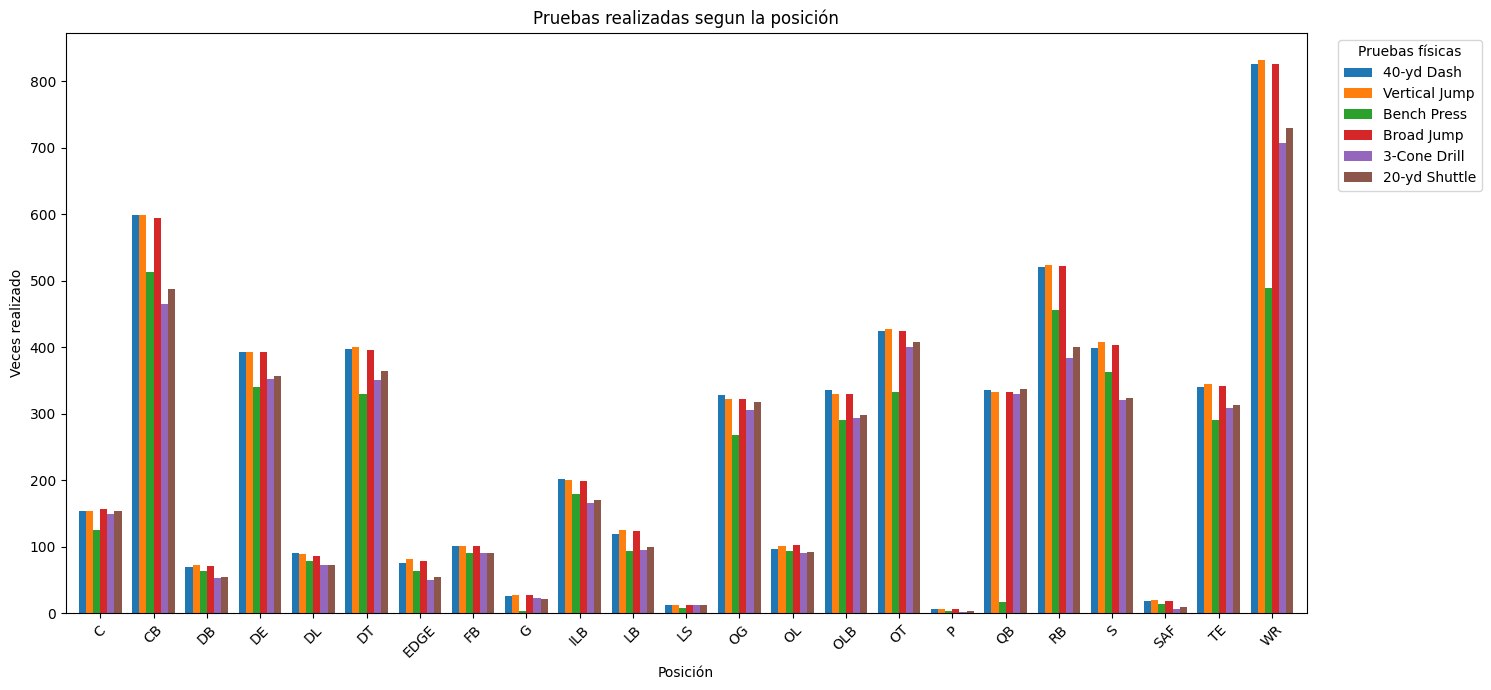

In [ ]:
pruebas_posicion = draft_pruebas.groupby('Position')[columnas_numericas].count()

pruebas_posicion.plot(kind='bar', figsize=(15, 7),width=0.8)

plt.title('Pruebas realizadas segun la posición')
plt.xlabel('Posición')
plt.ylabel('Veces realizado')
plt.xticks(rotation=45)
plt.legend(title='Pruebas físicas', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Mirando el grafico notamos que ciertas posiciones como la del punter o el kicker apenas tienen pruebas realizadas en el bench press, podemos entonces deducir que para la imputacion de datos deberiamos realizarla en funcion de las posiciones para no tener valores anomalos en posiciones que no procedan

Cuando falte algun valor lo pongo como la mediana

Una vez identificados los valores ausentes en las variables numéricas, se ha decidido realizar una imputación utilizando la mediana de cada variable agrupada por posición del jugador *Position*.

Esta decisión se basa en que las características físicas de los jugadores pueden variar considerablemente dependiendo de su posición en el campo. Por ejemplo, las exigencias físicas de un linebacker pueden ser diferentes a las de un wide receiver.

Por tanto, utilizar una única mediana global para todos los jugadores podría introducir cierta distorsión en los datos.


In [ ]:
draft_pruebas[columnas_numericas] = draft_pruebas.groupby('Position')[columnas_numericas].transform(lambda x: x.fillna(x.median())) #lo tengo que hacer con fillna, si igualo me lo cargo todo

Vemos que habiendo filtrado ya bajan bastante los porcentajes de valores nulos, aun asi, voy a comprobar que el porcentaje de seleccionados no se haya disparado al eliminar jugadores

Observamos que este filtro a eliminado mas jugadores no seleccionados que drafteados, aun asi la diferencia de eliminados no es especialmente grande

In [ ]:
print(draft_pruebas["Drafted"].value_counts()) #cuantos registros de drafteados me quedo tras los filtros
draft["Drafted"].value_counts() - draft_pruebas["Drafted"].value_counts() #Cuantos he perido respecto del original, para ver si pierdo mucho volumen de una opcion y pocos de mucha, de momento bien
draft_pruebas

Drafted
Y    3870
N    2086
Name: count, dtype: int64


,40-yd Dash,Vertical Jump,Bench Press,Broad Jump,3-Cone Drill,20-yd Shuttle,Position,Drafted
2,5.56,25.0,23.0,94.0,8.48,4.98,OT,Y
3,4.97,29.0,20.0,104.0,7.29,4.49,TE,N
4,4.55,34.0,14.0,123.0,7.18,4.15,CB,Y
7,4.72,31.0,21.0,112.0,7.96,4.39,OLB,N
9,4.44,35.0,17.0,119.0,7.03,4.14,CB,Y
...,...,...,...,...,...,...,...,...
8930,5.19,31.0,27.5,108.0,7.75,4.84,G,Y
8932,4.35,41.0,18.0,125.0,6.88,4.32,SAF,Y
8946,5.01,29.5,21.0,108.0,7.83,4.74,OT,N
8950,4.47,35.5,14.0,121.0,6.95,4.44,WR,Y


Ultima comprobacion para ver si siguen existiendo valores nulos

In [ ]:
draft_pruebas.isnull().sum()

,0
40-yd Dash,0
Vertical Jump,0
Bench Press,0
Broad Jump,0
3-Cone Drill,0
20-yd Shuttle,0
Position,0
Drafted,0


# 4. Codificar variables categoricas

In [ ]:
draft_onehot = pd.get_dummies(draft_pruebas, columns=['Position'], drop_first=True, dtype=int) #hago el one-hot, indico la columna, quito la primera para que no me salte lo del dummie y le indico que lo haga con int para poner valores de 1/0

In [ ]:
draft_onehot = pd.get_dummies(draft_onehot, columns=['Drafted'], drop_first=True, dtype=int)

In [ ]:
draft_onehot.head(2)

,40-yd Dash,Vertical Jump,Bench Press,Broad Jump,3-Cone Drill,20-yd Shuttle,Position_CB,Position_DB,Position_DE,Position_DL,...,Position_OLB,Position_OT,Position_P,Position_QB,Position_RB,Position_S,Position_SAF,Position_TE,Position_WR,Drafted_Y
2,5.56,25.0,23.0,94.0,8.48,4.98,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
3,4.97,29.0,20.0,104.0,7.29,4.49,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


# 5. Distribución de variables

Skewness: nos indica si la distribución está desplazada hacia valores altos o bajos. (si es + desviacion a la derecha)

Kurtosis: nos indica cómo son las colas de la distribución y si existen valores extremos respecto a una distribución normal.
  (Valores positivos: colas más pesadas que la normal ,
  Valores negativos: colas más ligeras que la normal, en el cero igual a districbucion normal)

In [ ]:
cols = columnas_numericas

for c in cols:
    print(f"------{c}------")
    print("Skewness: %f" % draft_pruebas[c].skew())
    print("Kurtosis: %f" % draft_pruebas[c].kurt())

------40-yd Dash------
Skewness: 0.776390
Kurtosis: -0.241153
------Vertical Jump------
Skewness: -0.176072
Kurtosis: -0.199678
------Bench Press------
Skewness: 0.302493
Kurtosis: 0.115963
------Broad Jump------
Skewness: -0.384925
Kurtosis: -0.084528
------3-Cone Drill------
Skewness: 0.882504
Kurtosis: 0.441851
------20-yd Shuttle------
Skewness: 0.721085
Kurtosis: 0.285983


Aqui solo veo en funcion de cada columna como estan repartidos los datos, en mi caso necesito tambien poder ver estas estadisticas cogiendo mi objetivo (si son drafteados o no) para ver como varian tambien los datos

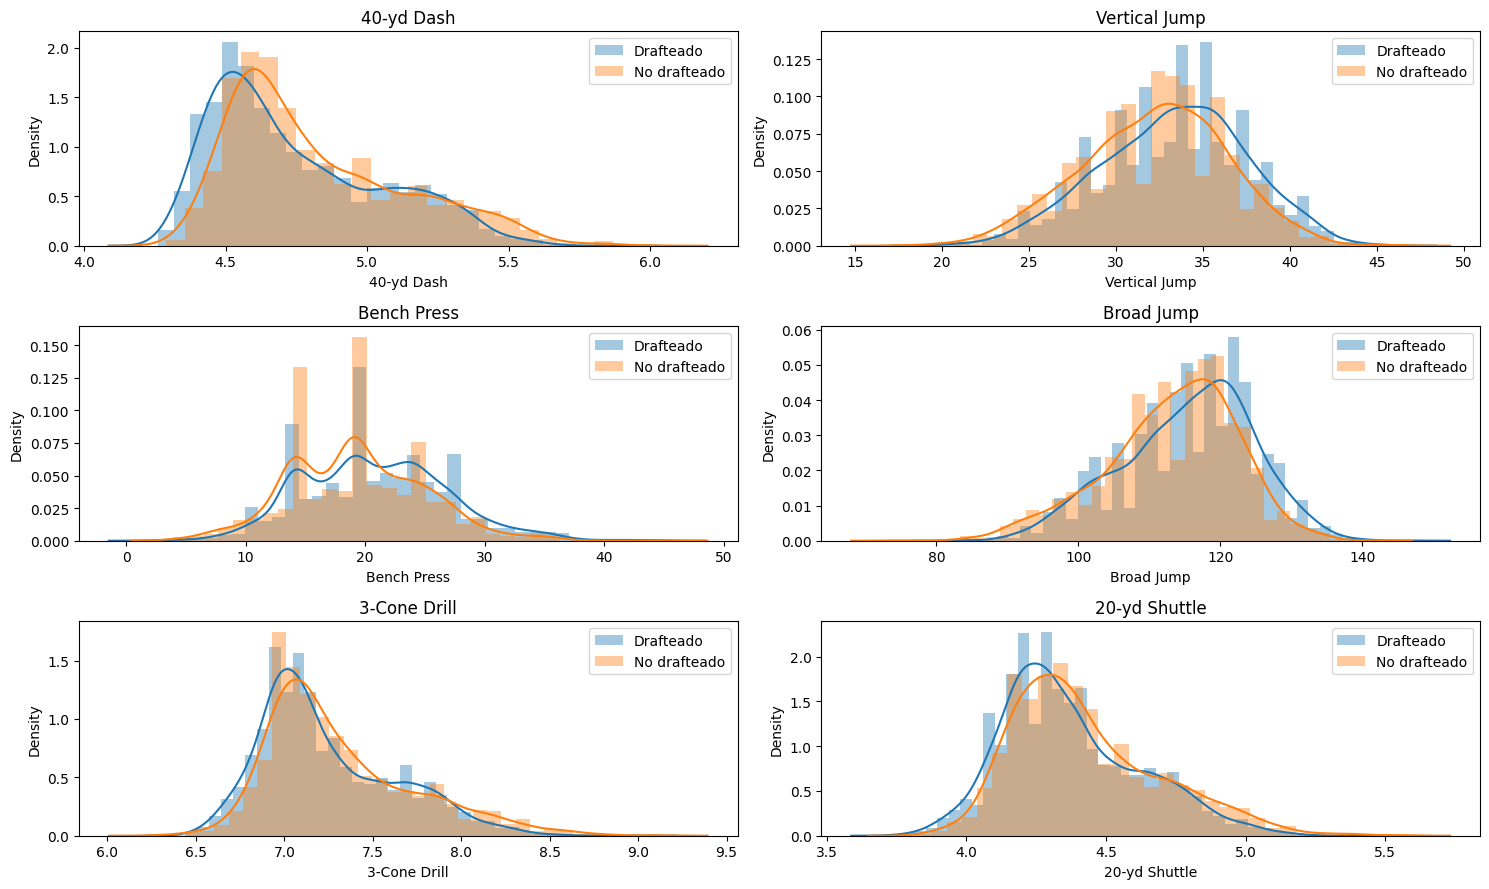

In [ ]:
cols = columnas_numericas

fig, ax = plt.subplots(nrows=3, ncols = 2, figsize = (15, 9))

i,j = 0,0
for c in cols:
    sns.distplot(draft_pruebas.query("Drafted == 'Y'")[c], hist = True, kde = True, ax = ax[i,j], label = 'Drafteado')
    sns.distplot(draft_pruebas.query("Drafted == 'N'")[c], hist = True, kde = True, ax = ax[i,j], label = 'No drafteado')

    ax[i,j].set_title(c)
    ax[i,j].legend()

    j+=1
    if j==2:
        i+=1
        j=0

plt.tight_layout()